# Maintain Multi-Velocity: Y-Bounds Visualization

Renders the arena with the rodent and draws lines at +/- y to help pick a `max_y` termination threshold.

In [1]:
%load_ext autoreload
%autoreload 2
import os
import sys

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

if sys.platform == "darwin":
    os.environ["MUJOCO_GL"] = "glfw"
else:
    os.environ["MUJOCO_GL"] = "egl"

import jax
import mujoco
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format='retina'

from scamper.environment.rodent.maintain_multi_velocity import (
    MaintainMultiVelocity,
    default_config,
)

In [2]:
# --- SET THIS ---
Y_BOUND = 0.15  # meters: lines will be drawn at +Y_BOUND and -Y_BOUND
# ----------------

In [3]:
cfg = default_config()
env = MaintainMultiVelocity(config=cfg)
model = env.mj_model
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)
print(f"Model compiled. Action size: {env.action_size}")

Model compiled. Action size: 38


In [4]:
def render_with_y_lines(model, data, y_bound, cam_kwargs, height=720, width=960):
    """Render a frame and overlay y-bound lines."""
    renderer = mujoco.Renderer(model, height=height, width=width)
    cam = mujoco.MjvCamera()
    cam.type = mujoco.mjtCamera.mjCAMERA_FREE
    cam.fixedcamid = -1
    cam.trackbodyid = -1
    cam.lookat[:] = cam_kwargs["lookat"]
    cam.distance = cam_kwargs["distance"]
    cam.azimuth = cam_kwargs["azimuth"]
    cam.elevation = cam_kwargs["elevation"]

    # Disable all labels
    renderer._scene_option.label = mujoco.mjtLabel.mjLABEL_NONE

    renderer.update_scene(data, camera=cam)

    # Add y-bound lines directly into the renderer's scene
    scene = renderer._scene
    x_range = 3.0
    for sign in [1, -1]:
        y = sign * y_bound
        if scene.ngeom < scene.maxgeom:
            g = scene.geoms[scene.ngeom]
            mujoco.mjv_connector(
                g,
                type=mujoco.mjtGeom.mjGEOM_CAPSULE,
                width=0.008,
                from_=np.array([-x_range, y, 0.001]),
                to=np.array([x_range, y, 0.001]),
            )
            g.rgba[:] = [1, 0, 0, 1]
            scene.ngeom += 1

    frame = renderer.render()
    renderer.close()
    return frame

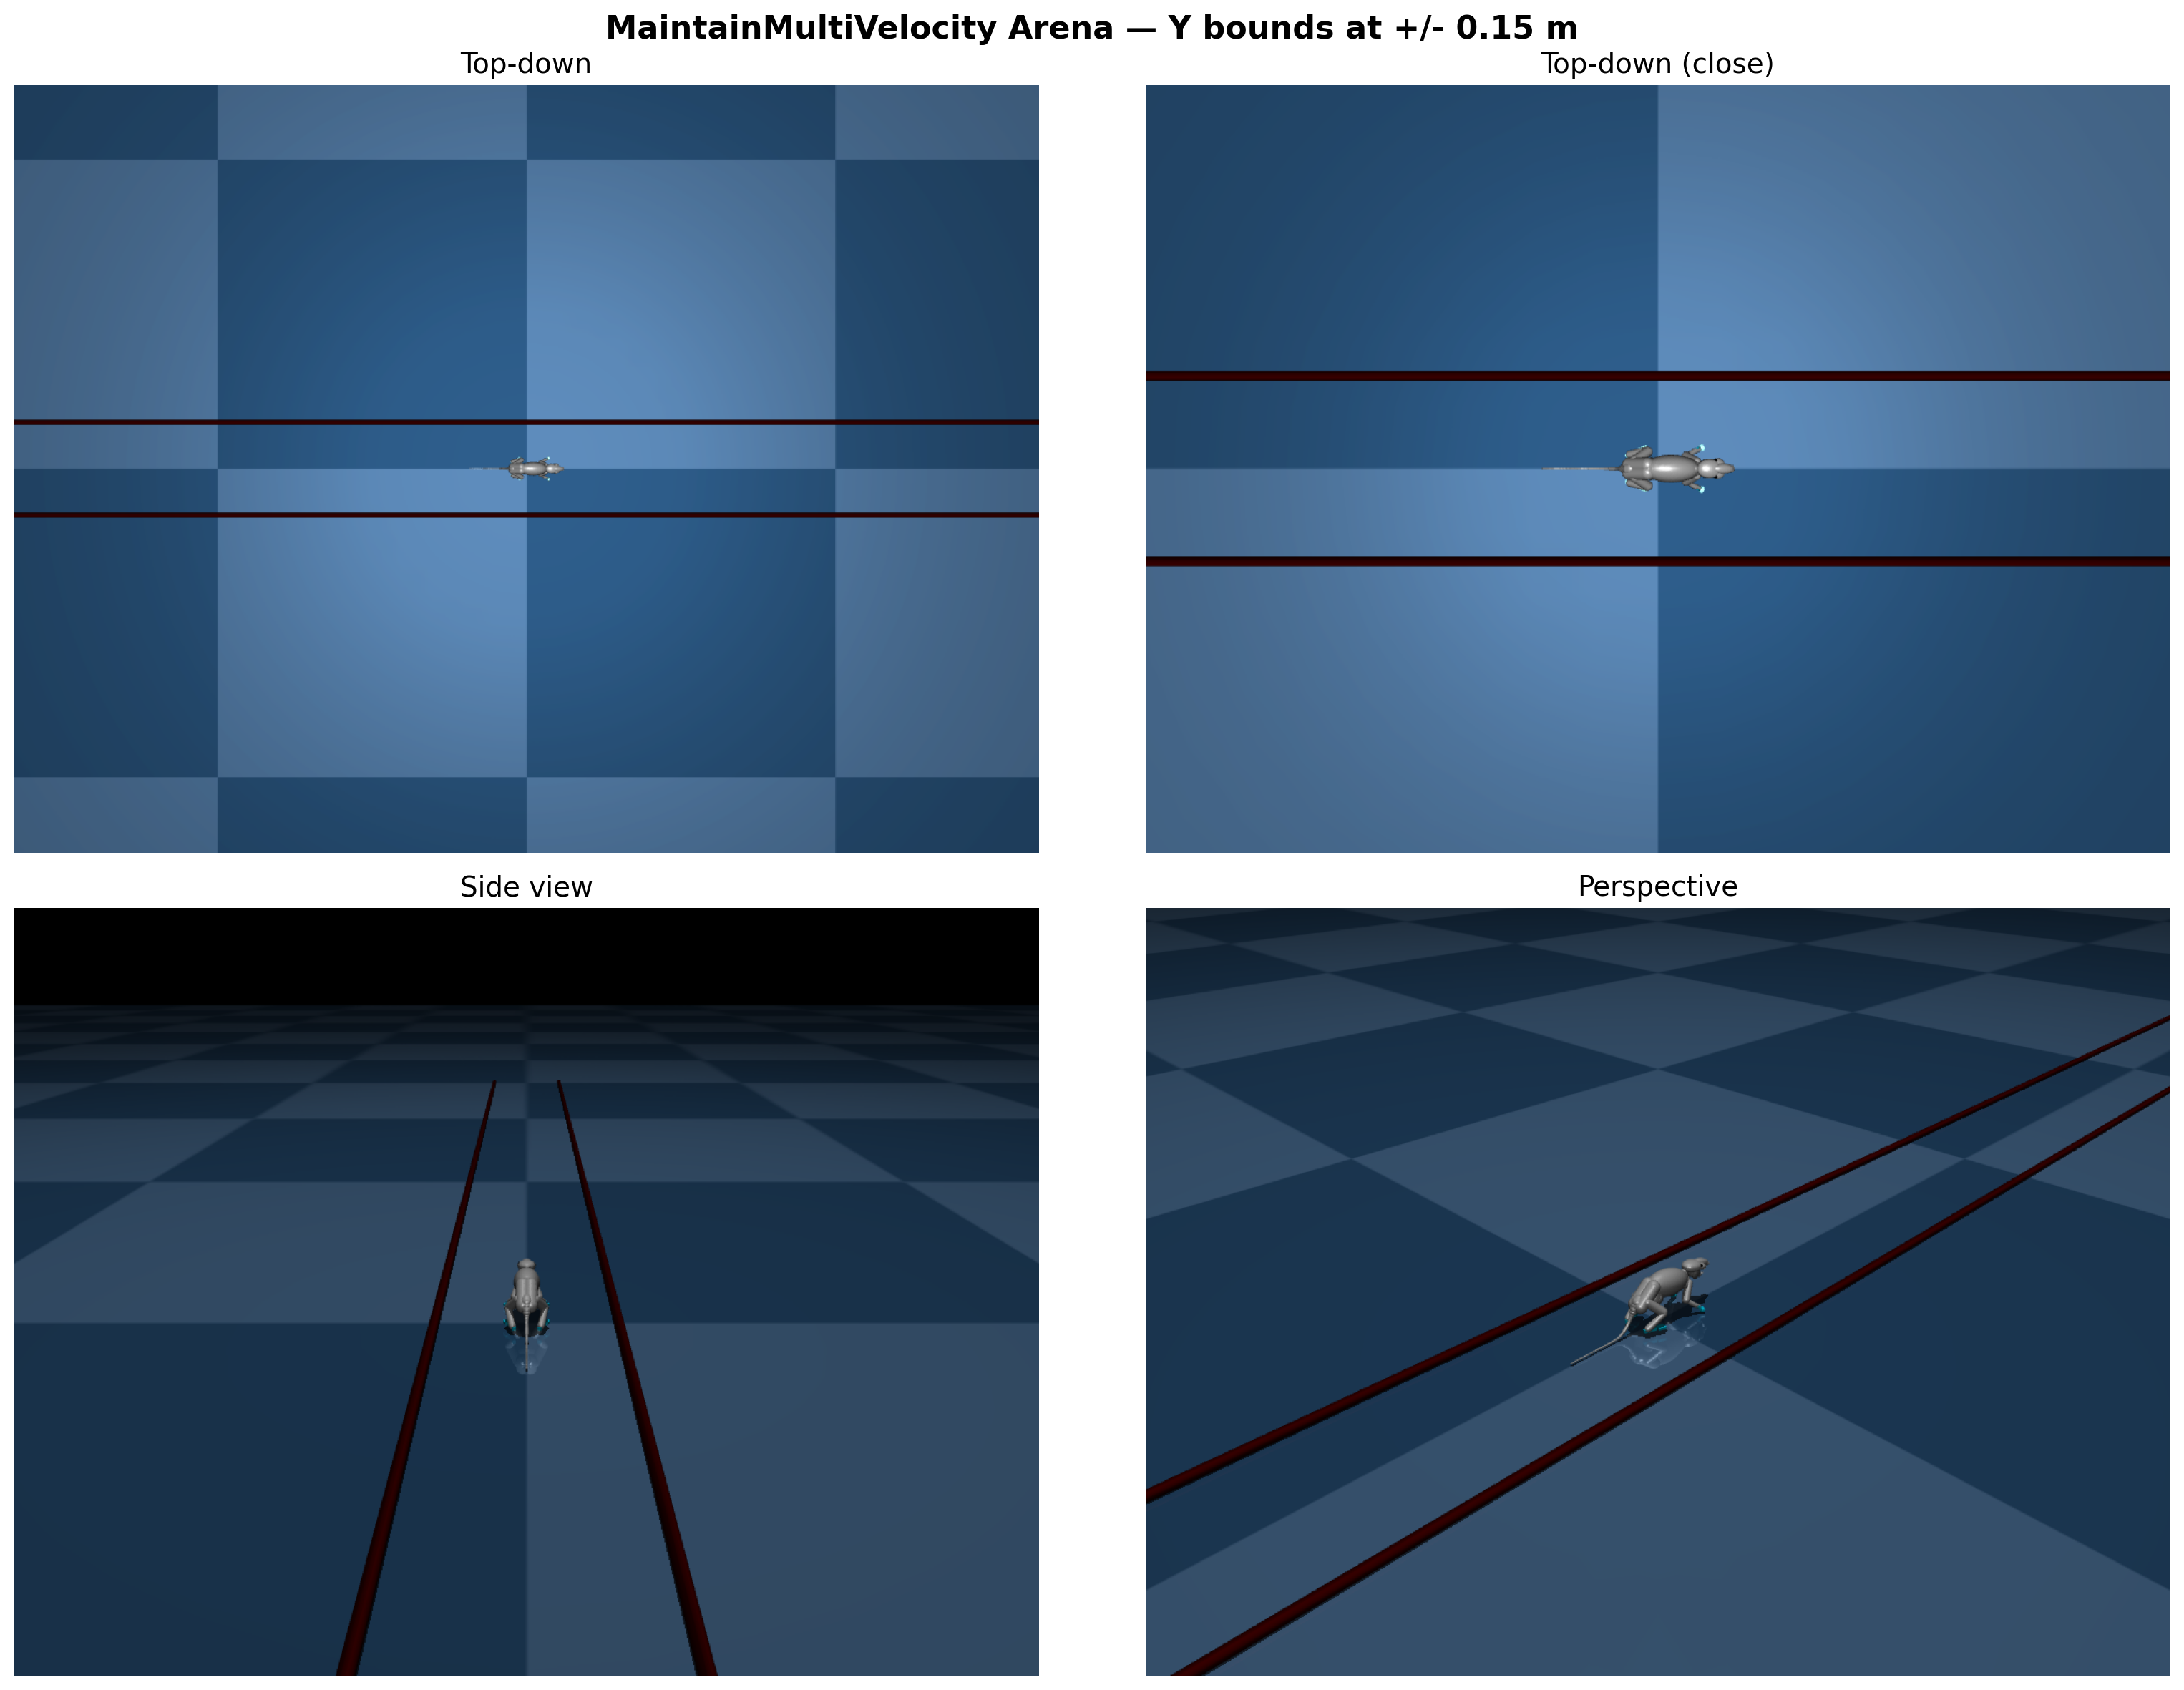

In [5]:
cameras = {
    "Top-down": dict(azimuth=90, elevation=-90, distance=3.0, lookat=[0.0, 0.0, 0.0]),
    "Top-down (close)": dict(
        azimuth=90, elevation=-90, distance=1.5, lookat=[0.0, 0.0, 0.0]
    ),
    "Side view": dict(azimuth=0, elevation=-20, distance=1.5, lookat=[0.0, 0.0, 0.05]),
    "Perspective": dict(
        azimuth=45, elevation=-30, distance=1.5, lookat=[0.0, 0.0, 0.05]
    ),
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, (name, cam_kwargs) in zip(axes.flat, cameras.items()):
    frame = render_with_y_lines(model, data, Y_BOUND, cam_kwargs)
    ax.imshow(frame)
    ax.set_title(name, fontsize=14)
    ax.axis("off")

plt.suptitle(
    f"MaintainMultiVelocity Arena — Y bounds at +/- {Y_BOUND} m",
    fontsize=16,
    fontweight="bold",
)
plt.tight_layout()
plt.show()